# 1. Imports

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_squared_error
import math

# 2. Load Dataset

In [5]:
df = pd.read_csv("/kaggle/input/google-stock-price/GOOG.csv")
print(df.head())         # Check first 5 rows
print(df.columns)        # See all column names
data = df['Close'].values.reshape(-1, 1)

         Date      Open      High       Low     Close  Adj Close     Volume
0  2004-08-19  2.490664  2.591785  2.390042  2.499133   2.499133  897427216
1  2004-08-20  2.515820  2.716817  2.503118  2.697639   2.697639  458857488
2  2004-08-23  2.758411  2.826406  2.716070  2.724787   2.724787  366857939
3  2004-08-24  2.770615  2.779581  2.579581  2.611960   2.611960  306396159
4  2004-08-25  2.614201  2.689918  2.587302  2.640104   2.640104  184645512
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')


# 3. Scaling

In [6]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)


# 4. Create training sequences

In [7]:
sequence_length = 60
x_train, y_train = [], []

for i in range(sequence_length, len(scaled_data)):
    x_train.append(scaled_data[i-sequence_length:i, 0])
    y_train.append(scaled_data[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))



# 5. Build LSTM Model

In [8]:

model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(x_train.shape[1], 1)))
model.add(Dropout(0.2))
model.add(LSTM(50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(25))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mean_squared_error')

I0000 00:00:1755246773.226630      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


# 6. Train Model

In [9]:
early_stop = EarlyStopping(monitor='loss', patience=5, restore_best_weights=True)

history = model.fit(x_train, y_train, batch_size=32, epochs=50, callbacks=[early_stop])

Epoch 1/50


I0000 00:00:1755246778.633584     116 cuda_dnn.cc:529] Loaded cuDNN version 90300


150/150 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.0270
Epoch 2/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0013
Epoch 3/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0014
Epoch 4/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 8.7629e-04
Epoch 5/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.1759e-04
Epoch 6/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 8.2289e-04
Epoch 7/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 9.3346e-04
Epoch 8/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 6.8176e-04
Epoch 9/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.3066e-04
Epoch 10/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 8.2519e-04
Epoch 11/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.5381e-04
Epoch 12/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.7806e-04
Epoch 13/50
150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 6.4281e-04


# 7. TEST & EVALUATE

In [10]:
train_data_len = int(len(data) * 0.8)
train_data = scaled_data[:train_data_len]
test_data = scaled_data[train_data_len - sequence_length:]

x_test, y_test = [], data[train_data_len:]

for i in range(sequence_length, len(test_data)):
    x_test.append(test_data[i-sequence_length:i, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

# Evaluate RMSE
rmse = math.sqrt(mean_squared_error(y_test, predictions))
print(f"Root Mean Squared Error: {rmse}")

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Root Mean Squared Error: 3.995517905729937


# 8. PLOT RESULTS

/tmp/ipykernel_36/258351167.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid['Predictions'] = predictions


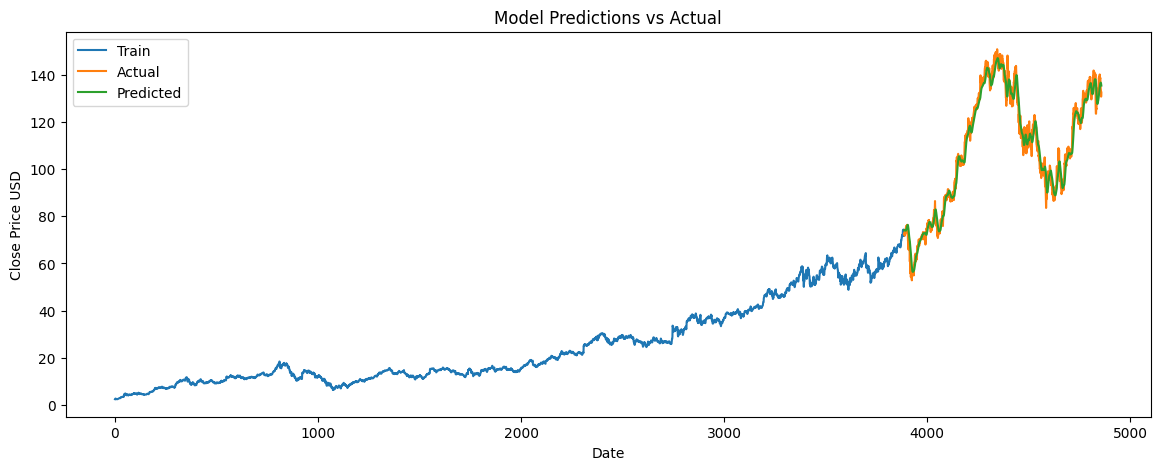

In [11]:
train = df[:train_data_len]
valid = df[train_data_len:]
valid['Predictions'] = predictions

plt.figure(figsize=(14,5))
plt.title('Model Predictions vs Actual')
plt.xlabel('Date')
plt.ylabel('Close Price USD')
plt.plot(train['Close'], label='Train')
plt.plot(valid['Close'], label='Actual')
plt.plot(valid['Predictions'], label='Predicted')
plt.legend()
plt.show()

# 8. FUTURE FORECAST (Next 30 Days)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━

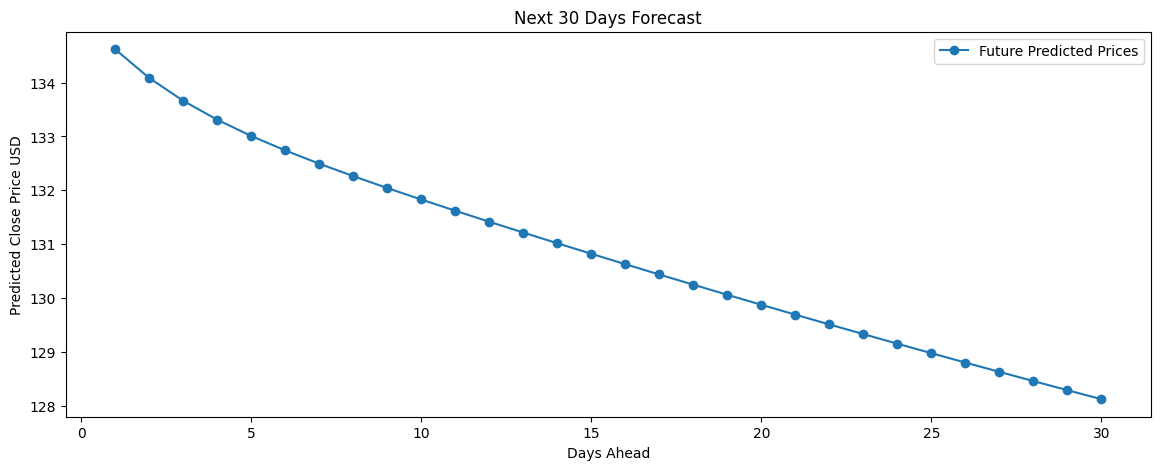

In [12]:

last_60_days = scaled_data[-sequence_length:]
future_input = last_60_days.reshape(1, sequence_length, 1)

future_predictions = []
for _ in range(30):
    pred_price = model.predict(future_input)[0][0]
    future_predictions.append(pred_price)

    # Append prediction and remove first element for sliding window
    future_input = np.append(future_input[:, 1:, :], [[[pred_price]]], axis=1)

# Convert back to actual prices
future_predictions = scaler.inverse_transform(np.array(future_predictions).reshape(-1, 1))

plt.figure(figsize=(14,5))
plt.plot(range(1, 31), future_predictions, marker='o', label='Future Predicted Prices')
plt.title('Next 30 Days Forecast')
plt.xlabel('Days Ahead')
plt.ylabel('Predicted Close Price USD')
plt.legend()
plt.show()
